In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from scipy.spatial.distance import mahalanobis
from scipy.special import softmax

## Dual AoA workflow for tessera embeddings and Sentinel-1 features

Use this section for both model outputs. It can:

- load a single parquet with a train/test split column, or separate train/test files
- infer feature columns automatically from numeric columns
- convert logits to predictions when a prediction column is missing
- run the full Mahalanobis AoA workflow twice and save one CSV per model



Running AoA for: Tessera embeddings
  Train rows: 197
  Test rows: 50
  Threshold: 6.9340
  Inside AoA: 96.00%
  Feature count: 34
  Saved: data\aoa_outputs\tessera_embeddings_aoa_results.csv


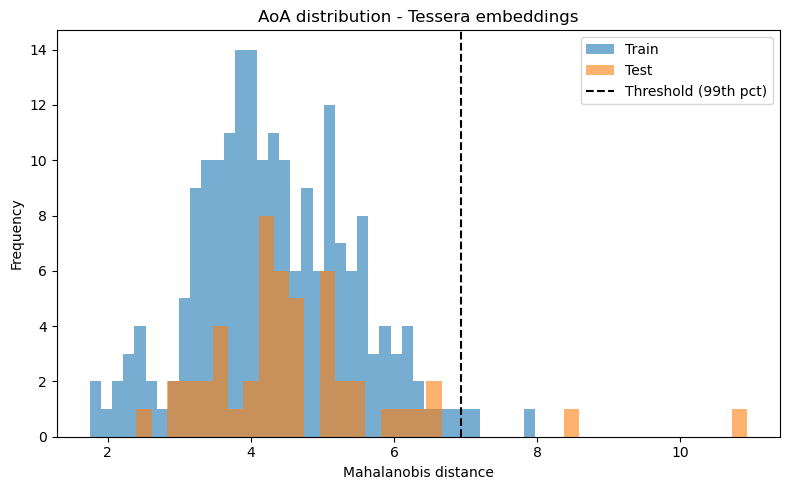


Running AoA for: Sentinel-1 features
  Train rows: 197
  Test rows: 50
  Threshold: 7.5463
  Inside AoA: 100.00%
  Feature count: 34
  Saved: data\aoa_outputs\sentinel_1_features_aoa_results.csv


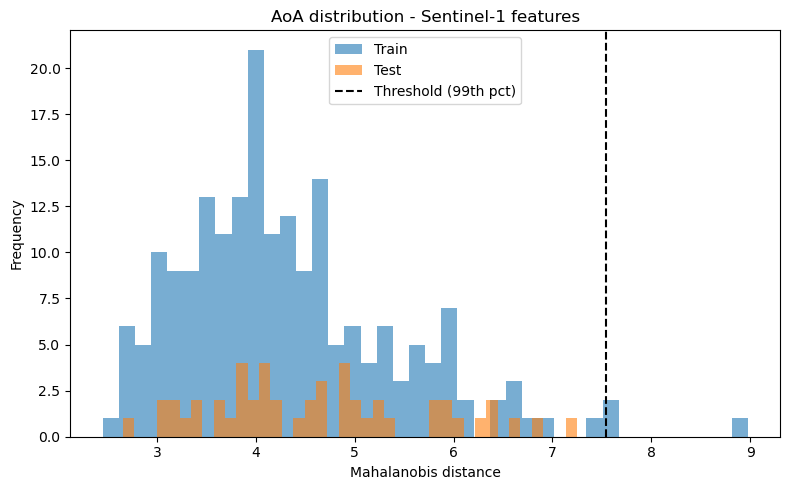


AoA summary:
               case  train_rows  test_rows  threshold  inside_aoa_percent                                           output_csv
 Tessera embeddings         197         50   6.933984                96.0  data\aoa_outputs\tessera_embeddings_aoa_results.csv
Sentinel-1 features         197         50   7.546287               100.0 data\aoa_outputs\sentinel_1_features_aoa_results.csv


In [8]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from scipy.spatial.distance import mahalanobis
from scipy.special import softmax


def mahalanobis_distance(x, mean, cov_inv):
    return mahalanobis(x, mean, cov_inv)


AOA_OUTPUT_DIR = Path("data/aoa_outputs")
AOA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

METADATA_COLUMNS = {
    "label",
    "prediction",
    "prediction_probability",
    "sample_id",
    "field_id",
    "geometry",
    "type",
    "split",
    "subset",
    "set",
    "phase",
    "train_test",
    "distance",
    "inside_aoa",
    "outside_aoa",
}
SPLIT_COLUMN_CANDIDATES = ["split", "subset", "set", "phase", "sample_split", "train_test"]


def slugify(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")



def load_table(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

    suffix = path.suffix.lower()
    if suffix == ".parquet":
        return pd.read_parquet(path)
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".feather":
        return pd.read_feather(path)

    raise ValueError(f"Unsupported file type: {path.suffix}")



def attach_prediction_from_logits(df):
    if "prediction" in df.columns:
        return df

    logit_cols = [
        c for c in df.columns
        if c.lower().startswith("pred_") or "logit" in c.lower()
    ]
    if not logit_cols:
        return df

    logits = df[logit_cols].to_numpy(dtype=float)
    out = df.copy()

    if logits.shape[1] == 1:
        prob_1 = 1.0 / (1.0 + np.exp(-logits[:, 0]))
        out["prediction"] = (prob_1 >= 0.5).astype(int)
        out["prediction_probability"] = np.maximum(prob_1, 1.0 - prob_1)
        return out

    probs = softmax(logits, axis=1)
    out["prediction"] = probs.argmax(axis=1)
    out["prediction_probability"] = probs.max(axis=1)
    return out



def detect_split_col(df, preferred=None):
    if preferred and preferred in df.columns:
        return preferred

    for col in SPLIT_COLUMN_CANDIDATES:
        if col in df.columns:
            return col
    return None



def split_train_test(df, case):
    if case.get("train_path") and case.get("test_path"):
        return load_table(case["train_path"]), load_table(case["test_path"])

    split_col = detect_split_col(df, case.get("split_col"))
    if split_col is None:
        raise ValueError(
            f"No split column found. Available columns: {list(df.columns)}"
        )

    train_value = str(case.get("train_value", "train")).strip().lower()
    test_value = str(case.get("test_value", "test")).strip().lower()
    split_series = df[split_col].astype(str).str.strip().str.lower()

    recognized_split_values = {train_value, test_value}
    if recognized_split_values.issubset(set(split_series.unique())):
        train_df = df.loc[split_series == train_value].copy()
        test_df = df.loc[split_series == test_value].copy()

        if train_df.empty or test_df.empty:
            raise ValueError(
                f"Split column '{split_col}' did not produce both train and test rows. "
                f"Unique values: {sorted(df[split_col].astype(str).unique())}"
            )

        return train_df, test_df

    group_col = case.get("group_col", "field_id")
    if group_col in df.columns:
        unique_groups = df[group_col].astype(str).drop_duplicates().to_numpy()
        test_fraction = float(case.get("test_fraction", 0.2))
        random_state = int(case.get("random_state", 42))
        train_groups, test_groups = train_test_split(
            unique_groups,
            test_size=test_fraction,
            random_state=random_state,
            shuffle=True,
        )
        train_df = df.loc[df[group_col].astype(str).isin(train_groups)].copy()
        test_df = df.loc[df[group_col].astype(str).isin(test_groups)].copy()
        if train_df.empty or test_df.empty:
            raise ValueError(
                f"Fallback group split on '{group_col}' did not produce both train and test rows."
            )
        return train_df, test_df

    raise ValueError(
        f"Split column '{split_col}' does not contain train/test labels and no usable group column was found. "
        f"Unique values: {sorted(df[split_col].astype(str).unique())}"
    )



def infer_feature_columns(df, exclude_cols=None):
    excluded = set(METADATA_COLUMNS)
    if exclude_cols:
        excluded.update(exclude_cols)

    feature_cols = [
        c for c in df.columns
        if c not in excluded and pd.api.types.is_numeric_dtype(df[c])
    ]

    if not feature_cols:
        raise ValueError(
            "No numeric feature columns found. Set 'feature_cols' explicitly in the case config."
        )

    return feature_cols



def build_matrices(train_df, test_df, feature_cols):
    train_features = train_df[feature_cols].apply(pd.to_numeric, errors="coerce")
    test_features = test_df[feature_cols].apply(pd.to_numeric, errors="coerce")

    train_means = train_features.mean()
    train_features = train_features.fillna(train_means)
    test_features = test_features.fillna(train_means)

    return train_features.to_numpy(dtype=float), test_features.to_numpy(dtype=float)



def run_aoa_case(case):
    if case.get("input_path"):
        combined_df = attach_prediction_from_logits(load_table(case["input_path"]))
        train_df, test_df = split_train_test(combined_df, case)
    else:
        if not case.get("train_path") or not case.get("test_path"):
            raise ValueError(
                f"Case '{case['name']}' needs either 'input_path' + split info or both 'train_path' and 'test_path'."
            )
        train_df = attach_prediction_from_logits(load_table(case["train_path"]))
        test_df = attach_prediction_from_logits(load_table(case["test_path"]))

    train_df = attach_prediction_from_logits(train_df)
    test_df = attach_prediction_from_logits(test_df)

    feature_cols = case.get("feature_cols") or infer_feature_columns(
        train_df,
        exclude_cols=case.get("exclude_cols"),
    )
    X_train, X_test = build_matrices(train_df, test_df, feature_cols)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    X_train_used = X_train_scaled
    X_test_used = X_test_scaled
    pca = None

    use_pca = case.get("use_pca", True)
    if use_pca and X_train_scaled.shape[1] > 1:
        max_components = min(X_train_scaled.shape[0] - 1, X_train_scaled.shape[1])
        if max_components >= 1:
            n_components = case.get("pca_components", min(20, max_components))
            n_components = max(1, min(n_components, max_components))
            if n_components < X_train_scaled.shape[1]:
                pca = PCA(n_components=n_components)
                X_train_used = pca.fit_transform(X_train_scaled)
                X_test_used = pca.transform(X_test_scaled)

    mean_vec = np.atleast_1d(np.mean(X_train_used, axis=0))
    cov_matrix = np.atleast_2d(np.cov(X_train_used, rowvar=False))
    cov_inv = np.linalg.pinv(cov_matrix)

    train_distances = np.array([
        mahalanobis_distance(x, mean_vec, cov_inv)
        for x in X_train_used
    ])
    test_distances = np.array([
        mahalanobis_distance(x, mean_vec, cov_inv)
        for x in X_test_used
    ])

    threshold_percentile = case.get("threshold_percentile", 99)
    threshold = np.percentile(train_distances, threshold_percentile)
    inside_aoa = test_distances <= threshold

    results = pd.DataFrame({
        "distance": test_distances,
        "inside_aoa": inside_aoa,
    })

    label_col = case.get("label_col", "label")
    prediction_col = case.get("prediction_col", "prediction")
    if label_col in test_df.columns:
        results["true_label"] = test_df[label_col].values
    if prediction_col in test_df.columns:
        results["prediction"] = test_df[prediction_col].values
    if "prediction_probability" in test_df.columns:
        results["prediction_probability"] = test_df["prediction_probability"].values

    for col in ["sample_id", "field_id", "type"]:
        if col in test_df.columns:
            results[col] = test_df[col].values

    results["aoa_case"] = case["name"]
    output_path = AOA_OUTPUT_DIR / f"{slugify(case['name'])}_aoa_results.csv"
    results.to_csv(output_path, index=False)

    return {
        "name": case["name"],
        "feature_cols": feature_cols,
        "threshold": threshold,
        "threshold_percentile": threshold_percentile,
        "train_distances": train_distances,
        "test_distances": test_distances,
        "results": results,
        "output_path": output_path,
        "inside_percent": float(np.mean(inside_aoa) * 100.0),
        "n_train": int(len(train_df)),
        "n_test": int(len(test_df)),
    }



def plot_aoa_case(result):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(result["train_distances"], bins=40, alpha=0.6, label="Train")
    ax.hist(result["test_distances"], bins=40, alpha=0.6, label="Test")
    ax.axvline(result["threshold"], linestyle="--", color="black", label=f"Threshold ({result['threshold_percentile']}th pct)")
    ax.set_xlabel("Mahalanobis distance")
    ax.set_ylabel("Frequency")
    ax.set_title(f"AoA distribution - {result['name']}")
    ax.legend()
    fig.tight_layout()
    fig.savefig(AOA_OUTPUT_DIR / f"{slugify(result['name'])}_distance_hist.png", dpi=300, bbox_inches="tight")
    plt.show()

    results = result["results"]
    if "true_label" not in results.columns or "prediction" not in results.columns:
        return

    valid = results["true_label"].notna() & results["prediction"].notna()
    if not valid.any():
        return

    misclassified = valid & (results["true_label"] != results["prediction"])
    correct = valid & ~misclassified

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(results.loc[correct, "distance"], bins=30, alpha=0.6, label="Correct")
    ax.hist(results.loc[misclassified, "distance"], bins=30, alpha=0.6, label="Misclassified")
    ax.axvline(result["threshold"], linestyle="--", color="black", label="Threshold")
    ax.set_xlabel("Mahalanobis distance")
    ax.set_ylabel("Frequency")
    ax.set_title(f"AoA distance by prediction correctness - {result['name']}")
    ax.legend()
    fig.tight_layout()
    fig.savefig(AOA_OUTPUT_DIR / f"{slugify(result['name'])}_correct_vs_wrong.png", dpi=300, bbox_inches="tight")
    plt.show()


AOA_CASES = [
    {
        "name": "Tessera embeddings",
        "input_path": Path("aoa_results_pixelencodernet_embedding_samples_crop_residues_crop3_fieldlevel_dalarna.parquet"),
        "split_col": "split",
        "group_col": "field_id",
        "test_fraction": 0.2,
        "random_state": 42,
        "label_col": "label",
        "prediction_col": "prediction",
        "use_pca": True,
        "pca_components": 20,
        "exclude_cols": ["split", "subset", "set", "sample_id", "field_id", "type", "geometry", "prediction_probability"],
    },
    {
        "name": "Sentinel-1 features",
        "input_path": Path("aoa_results_pixelencodernet_s1backcoh_samples_crop_residues_crop3_fieldlevel_dalarna.parquet"),
        "split_col": "split",
        "group_col": "field_id",
        "test_fraction": 0.2,
        "random_state": 42,
        "label_col": "label",
        "prediction_col": "prediction",
        "use_pca": True,
        "pca_components": 20,
        "exclude_cols": ["split", "subset", "set", "sample_id", "field_id", "type", "geometry", "prediction_probability"],
    },
]


aoa_case_results = []

for case in AOA_CASES:
    print(f"\nRunning AoA for: {case['name']}")
    try:
        result = run_aoa_case(case)
    except Exception as exc:
        print(f"  Skipped: {exc}")
        continue

    aoa_case_results.append(result)
    print(f"  Train rows: {result['n_train']}")
    print(f"  Test rows: {result['n_test']}")
    print(f"  Threshold: {result['threshold']:.4f}")
    print(f"  Inside AoA: {result['inside_percent']:.2f}%")
    print(f"  Feature count: {len(result['feature_cols'])}")
    print(f"  Saved: {result['output_path']}")
    plot_aoa_case(result)

if aoa_case_results:
    summary_df = pd.DataFrame([
        {
            "case": item["name"],
            "train_rows": item["n_train"],
            "test_rows": item["n_test"],
            "threshold": item["threshold"],
            "inside_aoa_percent": item["inside_percent"],
            "output_csv": str(item["output_path"]),
        }
        for item in aoa_case_results
    ])
    print("\nAoA summary:")
    print(summary_df.to_string(index=False))
else:
    print("\nNo AoA case could be run yet. Check that the parquet files exist and contain a split column or separate train/test files.")